<a href="https://colab.research.google.com/github/sancheznaranjoyairchayanne-design/tecnm-desarrollo-web/blob/main/laboratorios/sesion09/sesion09_laboratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Sesión 09 · Middleware Web, Intercepción y Logging de Transacciones

**Desarrollo de Aplicaciones Web (DAB-2201)** · TecNM Cancún  
**Docente:** MCC. Iván Márquez Larios (`ijmarquezl`)  
**Repositorio:** https://github.com/ijmarquezl/tecnm-desarrollo-web

> **La pregunta de hoy:** ¿Cómo mides cuánto tarda cada petición sin repetir código en cada endpoint? = "Usando un middleware"

- Mediante un middleware HTTP, que intercepta todas las peticiones, registra el tiempo antes y después de ejecutar el endpoint, calcula la duración y agrega el resultado a las cabeceras de la respuesta. De esta forma la lógica se implementa una sola vez y se aplica automáticamente a toda la API.

---

## 🖥️ Así se verá el resultado final

```http
$ curl -i http://127.0.0.1:8000/api/libros
HTTP/1.1 200 OK
content-type: application/json
x-process-time: 0.0017
x-request-id: 4f2c9a1e

{"libros":[]}

$ curl -i http://127.0.0.1:8000/api/libros \
       -H "X-Request-ID: prueba-123"
HTTP/1.1 200 OK
x-request-id: prueba-123
x-process-time: 0.0012

$ curl -i http://127.0.0.1:8000/api/no-existe
HTTP/1.1 404 Not Found
x-process-time: 0.0009
x-request-id: 7c1d...
```

_Si el cliente ya envía un X-Request-ID, se respeta; si no, el servidor genera uno._

**No hay pasos intermedios.** El cuaderno declara el resultado que debe existir al final; tú decides la estructura, los modelos y el orden de tu implementación. La celda de verificación compara tu resultado con este contrato.

---

## 🎯 Al finalizar podrás

- Explicar qué es un middleware y dónde se ejecuta.
- Agregar encabezados de trazabilidad a todas las respuestas.
- Verificar que el middleware también actúa en errores.

## ✅ Criterios de aceptación

El verificador ejecutará estos casos. Cada uno debe quedar en verde:

- [ ] Una respuesta correcta trae tiempo y traza → HTTP 200
- [ ] El X-Request-ID del cliente se conserva → HTTP 200
- [ ] El middleware también cubre los 404 → HTTP 404

## 🧩 El reto

Agrega un middleware que mida el tiempo de cada petición y propague un identificador de traza en todas las respuestas.

**Requisitos del contrato**

- Toda respuesta incluye X-Process-Time con un número decimal de segundos.
- Toda respuesta incluye X-Request-ID.
- Si la petición trae X-Request-ID, la respuesta conserva ese valor.
- El middleware también se aplica a respuestas 404.
- El endpoint GET /api/libros sigue respondiendo 200.

> **Pista conceptual:** El middleware envuelve la llamada al endpoint: mide antes y después, y agrega los encabezados a la respuesta que ya se construyó.

## 📦 Entregable

Cuaderno en verde y bitácora `auditorias/auditoria_sesion09.md` con una captura de las cabeceras.


## ⚙️ Preparación del entorno

Ejecuta esta celda una sola vez. Instala las herramientas del track **Python / FastAPI** y descarga el motor de verificación del repositorio. No necesitas instalar nada en tu computadora: todo corre en Colab.


In [1]:
import os, sys
print("⏳ Preparando el entorno de Desarrollo Web...")
!pip install -q fastapi uvicorn httpx pydantic "passlib[bcrypt]" bcrypt python-jose[cryptography] PyJWT "sqlalchemy[asyncio]" greenlet aiosqlite alembic python-multipart
!wget -q -O verificar.py https://raw.githubusercontent.com/ijmarquezl/tecnm-desarrollo-web/c275993ba69ef2a8cf650b2f127b55c8356279d7/laboratorios/verificar.py
if not os.path.exists("verificar.py") or os.path.getsize("verificar.py") < 1000:
    raise RuntimeError("No se pudo descargar verificar.py. Revisa tu conexión o abre el cuaderno desde el repositorio del curso.")
print("✅ Entorno listo")
print("Python:", sys.version.split()[0])
print("Motor de verificación:", os.path.getsize("verificar.py"), "bytes")


⏳ Preparando el entorno de Desarrollo Web...
✅ Entorno listo
Python: 3.13.18
Motor de verificación: 13395 bytes


## 🧩 El reto: escribe el resultado

Crea el o los archivos del contrato. No hay una plantilla de pasos: el esqueleto solo te da el punto de partida. Todo lo que sigue lo decides tú.

**Archivos que debes producir:** `app.py`


### 📄 `app.py`

Archivo principal de la implementación.

In [3]:
%%writefile app.py
from fastapi import FastAPI, Request
import time
import uuid

app = FastAPI(title="Todas tus respuestas llevarán estas cabeceras")


@app.middleware("http")
async def trazabilidad(request: Request, call_next):
    inicio = time.perf_counter()

    request_id = request.headers.get(
        "X-Request-ID",
        uuid.uuid4().hex[:8]
    )

    response = await call_next(request)

    response.headers["X-Process-Time"] = (
        f"{time.perf_counter() - inicio:.4f}"
    )
    response.headers["X-Request-ID"] = request_id

    return response


@app.get("/api/libros")
async def obtener_libros():
    return {"libros": []}

Overwriting app.py


## 🧪 Tu contrato C-R-E-O

Antes de pedir ayuda a la IA, escribe el contrato que describe el resultado. Esto alimenta tu bitácora y te obliga a pensar como arquitecto:

| Elemento | Tu definición |
| :--- | :--- |
| **Contexto** | Aplicación desarrollada con FastAPI en un entorno de Google Colab. Se debe implementar un middleware HTTP que funcione para todas las rutas y respuestas, incluidas las respuestas de error 404. |
| **Rol** | Actuar como desarrollador backend especializado en APIs REST con FastAPI, aplicando buenas prácticas de trazabilidad e intercepción de peticiones.|
| **Especificación** | La API debe exponer la ruta GET /api/libros, que responde con {"libros":[]} y código HTTP 200. Todas las respuestas deben incluir los encabezados X-Process-Time y X-Request-ID. Si el cliente envía X-Request-ID, el servidor debe conservarlo; de lo contrario, debe generar uno nuevo. El middleware también debe actuar sobre respuestas HTTP 404.|
| **Output** |Archivo app.py funcional que cumpla el contrato, supere la verificación automática del laboratorio y genere las cabeceras de trazabilidad requeridas en todas las respuestas HTTP. |

> No pegues código de la IA sin auditarlo. La responsabilidad técnica del resultado es tuya.


## 🔍 Verificación del resultado

Ejecuta esta celda cuando tu implementación esté lista. La verificación no modifica tu código: solo observa el comportamiento y compara con el contrato. Si algo falla, el mensaje te dice **qué esperaba** y **qué recibió**.


In [4]:
from verificar import probar_http

casos = [{'descripcion': 'Una respuesta correcta trae tiempo y traza',
  'metodo': 'GET',
  'ruta': '/api/libros',
  'estado': 200,
  'headers_contiene': {'x-process-time': '', 'x-request-id': ''}},
 {'descripcion': 'El X-Request-ID del cliente se conserva',
  'metodo': 'GET',
  'ruta': '/api/libros',
  'headers': {'X-Request-ID': 'prueba-123'},
  'estado': 200,
  'headers_contiene': {'x-request-id': 'prueba-123'}},
 {'descripcion': 'El middleware también cubre los 404',
  'metodo': 'GET',
  'ruta': '/api/no-existe',
  'estado': 404,
  'headers_contiene': {'x-process-time': '', 'x-request-id': ''}}]

probar_http(casos, archivo="app.py", limpiar=[], env={})


VERIFICACIÓN DEL RESULTADO · 3 casos · app.py
✅ 01. Una respuesta correcta trae tiempo y traza
✅ 02. El X-Request-ID del cliente se conserva
✅ 03. El middleware también cubre los 404
------------------------------------------------------------------------------
RESULTADO: 3/3 casos correctos. ¡Resultado logrado!


## 📝 Cierre y bitácora

1. Copia la plantilla `plantillas/auditoria_sesion09.md` a `auditorias/auditoria_sesion09.md` en tu fork.
2. Responde con tus palabras:
   - ¿Qué resultado te costó más alcanzar y por qué? = Lograr que el middleware añadiera los encabezados también en las respuestas 404, porque inicialmente pensé que solo afectaba a los endpoints definidos.

   - ¿Qué decisión de diseño tomaste que no estaba escrita en el contrato? = Decidí generar el identificador de traza usando uuid.uuid4().hex[:8] para obtener valores cortos y fáciles de leer.

   - ¿Qué error detectó la verificación que tú no habías previsto? = Que no bastaba con devolver una respuesta 200 correcta; también era necesario comprobar que los encabezados estuvieran presentes en las respuestas de error 404.

3. Haz commit de tu cuaderno ejecutado y de tu bitácora.

**La sesión termina cuando el resultado está en verde, no cuando el código "parece funcionar".**
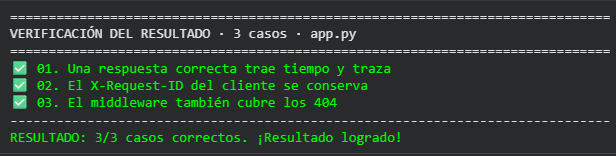
